# 10.1 Fairness and Transparency

In [1]:
# %pip install fairlearn lime

In [2]:
import warnings
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import Lasso
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import fbeta_score
from sklearn.metrics import recall_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import confusion_matrix
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import RidgeClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from lime import lime_tabular
from IPython.display import display, HTML

import fairlearn.metrics as flm
from fairlearn.reductions import DemographicParity, ExponentiatedGradient
from fairlearn.metrics import MetricFrame
from fairlearn.metrics import selection_rate
from fairlearn.postprocessing import ThresholdOptimizer

warnings.filterwarnings("ignore", category=FutureWarning)

## Welcome to the FIM Bank

At the FIM Bank we have different tiers of customers. People with an estimated income of more than 50k a year receive special treatment with superior products and better credit conditions. However, we keep struggling with our ranking policy. Some of our clients turned out to have lower incomes than expected which lead to severe losses. Other clientes complained about unfair treatment and accused our account managers of discrimination.

### Current Process

Our current process looks like this:
* People apply for a credit and provide their data: demographics, education, occupation, financial history (e.g., Schufa-Auskunft).
* A loan officer estimates the income of the applicant based on past experience and sympathy.
* If the applicant is expected to earn more than 50k, he or she is granted superior status; otherwise, he or she is offered less favorable conditions.

### Your Mission

We need you to revise our ranking process. Therefore, you should design a ML model that selects the "right" clients for superior status. Develop a simple ML model that makes a binary decision about applicants' customer tiers, as depicted in this sketch. Positive means income >50k, negative means income <=50k.

<div style="display: flex; justify-content: center; align-items: center;">
  <div style="display: flex; justify-content: center; align-items: center; padding: 10px; background-color: white;">
    <img src="img\Classification.jpg" style="max-height: 500px;">
  </div>
</div>

The ranking decision should fulfill three objectives. You will be confronted with several normative and economic tradeoff decisions along the way. **Please make notes about your tradeoff decisions or engage in a discussion with your colleagues.**

#### Business Objective
**To maximize our profits you should correctly identify and select the clients that deserve superior conditions.**

#### Fairness Objective
**At the same time, please make sure that everyone is treated fairly. It is up to you to determine what fair is - just make sure to be explicit about your motivation.**

#### Transparency Objective
**The model should make justifiable decisions and allow for human supervision.**

## Data Understanding: These are our clients
Luckily, we gathered historical data on our clients' income. Here you find details about data collection and feature descriptions:
* **age**: the age of the individual in years,
* **workclass**: the industry / sector that the individual works in.
* **education-num**: a numeric form of the highest level of education achieved,
* **marital_status**: the marital status of the individual,
* **occupation**: the occupation of the individual,
* **race**: the individual's race,
* **sex**: the individual's sex,
* **capital_gain**: capital gain in the previous year,
* **capital_loss**: capital loss in the previous year,
* **hours_per_week**: hours worked per week,
* **native_country**: the native country of the individual

To start off, please...
* Familiarize yourself with the data at hand. 
* Take a look at the features and labels. 
* Plot some feature distributions.

### Data Overview

In [3]:
data_path = next(
    (parent / 'data' / '10_fairness_dataset.csv'
     for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / 'data' / '10_fairness_dataset.csv').is_file()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        'Could not find data/10_fairness_dataset.csv in the repository.'
    )

# load dataset with slight formal preprocessing
dataset = (
    pd.read_csv(data_path, sep=';', encoding='ISO-8859-1')
    .rename(columns={"ï»¿Age": "age"})
    .drop(columns=["fnlwgt", "relationship", "education"]) # drop redundant variables
)

In [4]:
# a glimpse into the dataset
print("\nThe dataset contains", dataset.shape[0], "data points and", dataset.shape[1], "features.\n")
dataset.head()


The dataset contains 32561 data points and 12 features.



,age,workclass,education-num,marital-status,occupation,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,13,Never-married,Adm-clerical,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,White,Male,0,0,13,United-States,<=50K
2,38,Private,9,Divorced,Handlers-cleaners,White,Male,0,0,40,United-States,<=50K
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Black,Male,0,0,40,United-States,<=50K
4,28,Private,13,Married-civ-spouse,Prof-specialty,Black,Female,0,0,40,Cuba,<=50K


###  Feature Overview

In [5]:
# mean, standard deviation, min/max values, and quantiles of the numerical features
dataset.describe()

,age,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,10.080679,1077.648844,87.303830,40.437456
std,13.640433,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.000000,0.000000,0.000000,1.000000
25%,28.000000,9.000000,0.000000,0.000000,40.000000
50%,37.000000,10.000000,0.000000,0.000000,40.000000
75%,48.000000,12.000000,0.000000,0.000000,45.000000
max,90.000000,16.000000,99999.000000,4356.000000,99.000000


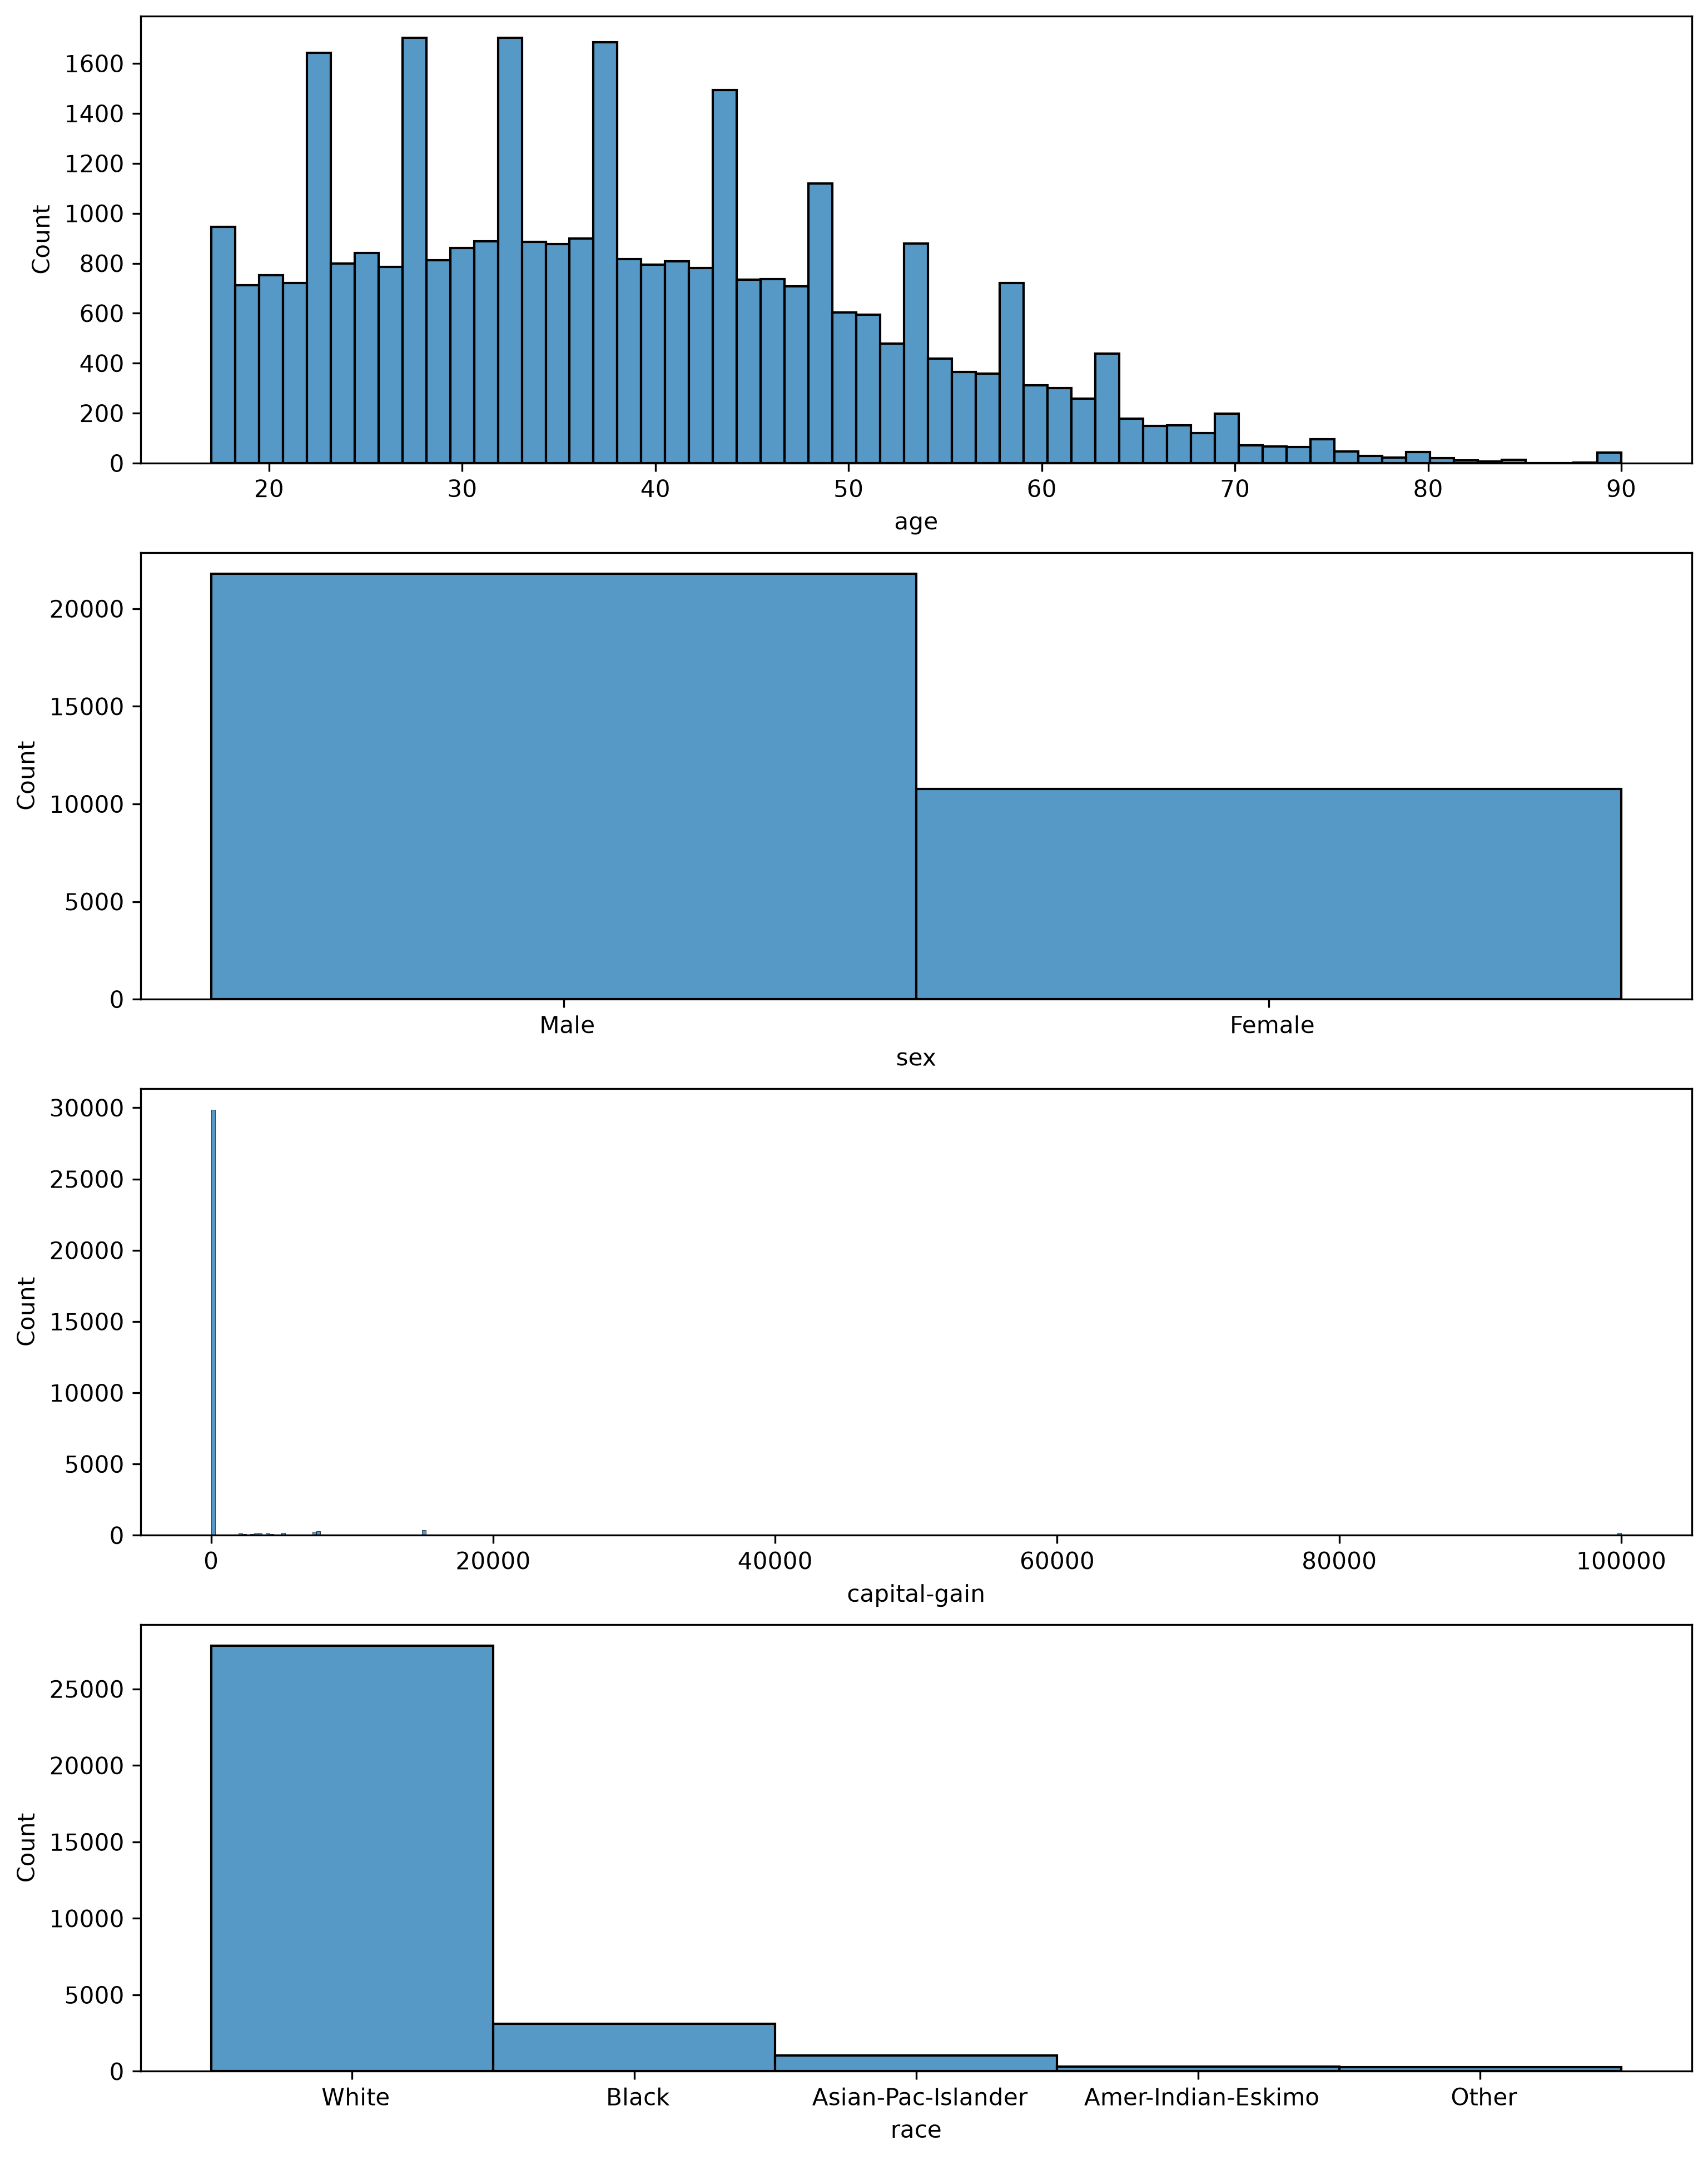

In [6]:
### YOUR INPUT HERE ###
# enter the feature names you want to visualize
feature_names = ["age", "sex", "capital-gain", "race"]
### YOUR INPUT HERE ###

if len(feature_names) == 1:
    sns.histplot(data=dataset, x=feature_names[0])
else:
    fig, axes = plt.subplots(nrows=len(feature_names), ncols=1, figsize=(12,len(feature_names)*4), dpi=300)
    for i, name in enumerate(feature_names):
        sns.histplot(data=dataset, x=name, ax=axes[i])

## Data Preprocessing

### Missing values
Before using our data to train a model, we need to some basic data preprocessing. Let's start with removing missing values.

In [7]:
# remove missing values
dataset = dataset.dropna()

#### Categorical Features
We have several categorical features with many values that need to be translated into a machine-readable format.

In [8]:
# we group age into 10-year bins
dataset['age'] = pd.cut(dataset['age'], bins=np.arange(10, 90, 10), right=False)
age_mapping = {interval: idx for idx, interval in enumerate(dataset['age'].cat.categories)}
dataset['age'] = dataset['age'].cat.codes
# binary encoding for female (0) and male (1)
sex_mapping = {' Female': 0, ' Male': 1}
dataset['sex'] = dataset['sex'].replace(sex_mapping)
# for simplicity we differentiate between white (0) and "others" (1)
race_mapping = {' White': 0, ' Black': 1, ' Asian-Pac-Islander': 1, ' Amer-Indian-Eskimo': 1, ' Other': 1}
dataset['race'] = dataset['race'].replace(race_mapping)
# the target variable (income) is grouped into two classes: less than or equal to 50K (0) and greater than 50K (1)
income_mapping = {' <=50K': 0, ' >50K': 1}
dataset['income'] = dataset['income'].replace(income_mapping)

# features with multiple categories
categorical_features = ['workclass', 'marital-status', 'occupation', 'native-country']

# one-hot encoding for categorical features
encoded_categorical = pd.get_dummies(dataset[categorical_features], dtype=int)
dataset = pd.concat([dataset.drop(categorical_features, axis=1), encoded_categorical], axis=1)

In [9]:
dataset.describe()

,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_ ?,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Never-worked,workclass_ Private,...,native-country_ Portugal,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia
count,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,...,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,2.379503,10.080679,1077.648844,87.303830,40.437456,0.056386,0.029483,0.064279,0.000215,0.697030,...,0.001136,0.003501,0.000369,0.002457,0.001566,0.000553,0.000584,0.895857,0.002058,0.000491
std,1.382048,2.572720,7385.292085,402.960219,12.347429,0.230670,0.169159,0.245254,0.014661,0.459549,...,0.033691,0.059068,0.019194,0.049507,0.039546,0.023506,0.024149,0.305451,0.045316,0.022162
min,-1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,9.000000,0.000000,0.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,2.000000,10.000000,0.000000,0.000000,40.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,3.000000,12.000000,0.000000,0.000000,45.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,6.000000,16.000000,99999.000000,4356.000000,99.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Train-Test Split
To avoid overfitting, we create a test set of unseen data that we can use for evaluation later on.

In [10]:
# define training and target features
X = dataset.drop('income', axis=1)
y = dataset['income']

# train, test split. 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert back to DataFrames with column names
X_train_df = pd.DataFrame(X_train)
X_test_df = pd.DataFrame(X_test)

### Scaling
Finally, we apply some statistical methods to scale the values into comparable ranges.

In [11]:
numerical_features = ["race", "sex", "age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
target = 'income'

# Save indices before scaling
train_index = X_train_df.index
test_index = X_test_df.index

# minmax because we can not assume standard distribution for our numerical features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_df[numerical_features])
X_test_scaled = scaler.transform(X_test_df[numerical_features])

# Convert back to DataFrames with column names PRESERVED
X_train_df = pd.DataFrame(X_train_scaled, columns=numerical_features, index=train_index)
X_test_df = pd.DataFrame(X_test_scaled, columns=numerical_features, index=test_index)

Notes:

* 

### Feature Selection
To reduce our feature space to a manageable size, we need to select the most relevant features. `Lasso (Least Absolute Shrinkage and Selection Operator)` is a regression method that attempts to reduce the number of features used in a model by setting some of the coefficients to zero. Features whose coefficients have been reduced to zero are not included in the model. In addition to ordinary linear regression, it adds a cost function (loss function) that is to be minimized. The **alpha value** stands for the regularization strength, which controls the effects of the regularization on the model.

In [12]:
# choose the feature selection strategy
selection_strategy = 'Lasso'
alpha = 0.001               # needed for Lasso regression

# select most important features based on Lasso regression
sel_ = SelectFromModel(Lasso(alpha=alpha, random_state=10))
sel_.fit(X_train_df, y_train)
selected_features = list(sel_.get_feature_names_out())

# Add sensitive features to selected features
selected_features.extend(['race', 'sex', 'age'])
# Remove duplicates while preserving order
selected_features = list(dict.fromkeys(selected_features))

# Filter X_train and X_test to only include selected features
X_train_df = X_train_df[selected_features]
X_test_df = X_test_df[selected_features]

# check whether our preprocessed data are ready for training
X_train_df.describe()

,race,sex,age,education-num,capital-gain,capital-loss,hours-per-week
count,26048.000000,26048.000000,26048.000000,26048.000000,26048.000000,26048.000000,26048.000000
mean,0.146921,0.668113,0.482889,0.605370,0.010536,0.020199,0.401924
std,0.354034,0.470900,0.197588,0.171680,0.072309,0.092661,0.125828
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.285714,0.533333,0.000000,0.000000,0.397959
50%,0.000000,1.000000,0.428571,0.600000,0.000000,0.000000,0.397959
75%,0.000000,1.000000,0.571429,0.733333,0.000000,0.000000,0.448980
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Correlation matrix

**TASK 1: Take a look at the correlations with sensitive attributes. What implications could this have for fairness? If you have removed some sensitive features, would you like to remove correlated features as well?**

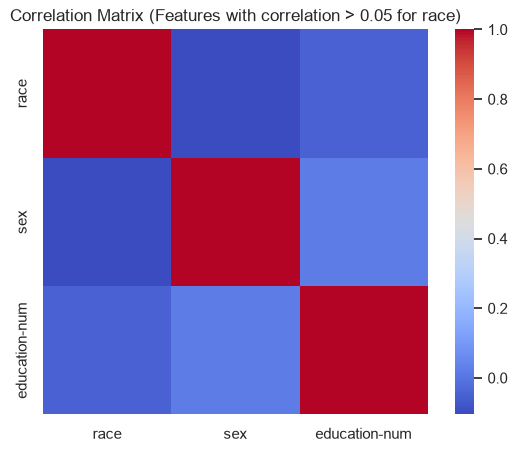

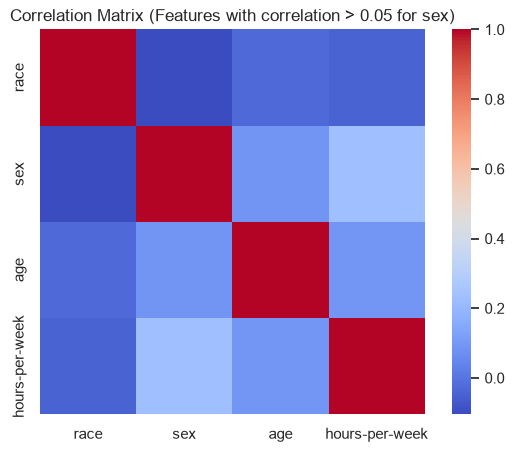

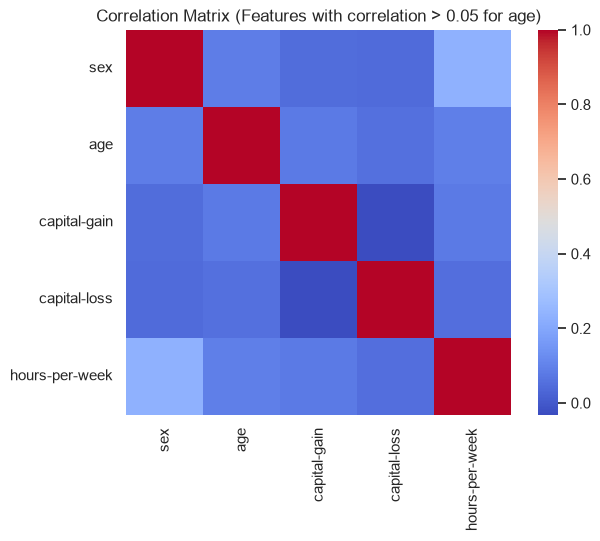

In [13]:
# compute correlation matrix for all features
correlation_matrix = X_train_df.corr()
correlation_threshold = 0.05 # set threshold for minimum correlation with sensitive attributes

# leave out uncorrelated features below threshold for overview
for feature in ["race", "sex", "age"]:
    correlation = correlation_matrix[feature].abs() > correlation_threshold
    correlation_subset = correlation_matrix.loc[correlation, correlation]

# plot reduced correlation matrix
    sns.set(style="white")
    plt.figure(figsize=(7, 5))
    sns.heatmap(correlation_subset, ax=plt.gca(), cmap="coolwarm", fmt=".2f", square=True)
    plt.title(f"Correlation Matrix (Features with correlation > {correlation_threshold} for {feature})")
    plt.show()

**TASK 2: Do you want to include or exclude sensitive features for the training later on? You can choose to treat them with a special careful focus or remove them entirely.**
* `sex`
* `age`
* `race`

In [14]:
### YOUR INPUT HERE ###
# Which (potentially) sensitive features do you want to focus on explicitly? Choose 2 at max
selected_sensitive_features = ["race", "sex"]
### YOUR INPUT HERE ###

### YOUR INPUT HERE ###
# Do you want to remove any sensitive features?
removed_features = []
### YOUR INPUT HERE ###

# remove selected sensitive features 
columns_to_remove = [X_train_df.columns.get_loc(col) for col in removed_features if col in X_train_df.columns]
X_train_df = X_train_df.drop(columns=removed_features)
X_test_df = X_test_df.drop(columns=removed_features)

## Model Training

**TASK 3: Which training algorithm do you want to use? How do you want to weight classes (we will return to this after the first evaluation)?**

* `Linear Regression` classifies indviduals based on a probability threshold. Features are additive and directly interpretable.

* `Decision Trees` partition the dataset into subgroups and create rules for each node based on the characteristics. For a small number of nodes, decision trees are intuitively interpretable.

* `Random Forest` is an ensemble method based on decision trees. It creates a large number of decision trees and combines their predictions to achieve more robust and accurate regression results. However, interpretation is more difficult and imprecise.

* `MLP Classifiers` are basically artificial neural networks and super powerful in learning non-linear relationships. However, we need to rely on model-agnostic XAI tools like LIME to approximate feature importance. Also, in our use case it is not possible to apply unfairness mitigation on MLP Classifiers.

### Parameter Tuning
Choose one model for training and specify the parameters. Ignore the rest of the models.

In [15]:
# model_name = "Linear Regression"
y_train = y_train.astype(int)

class_weight = {
    0:1/6, # weight for negative class (<= 50K)
    1:5/6} # weight for positive class (>50K)
lr = RidgeClassifier(alpha=0.1, class_weight=class_weight).fit(X_train_df, y_train)

In [16]:
# model_name = "Decision Tree"

max_depth = 10 # maximum level of decision nodes, the higher the more complex (but also the more prone to overfitting)
class_weight = {
    0:1/6, # weight for negative class (<= 50K)
    1:5/6} # weight for positive class (>50K)
dt = DecisionTreeClassifier(max_depth=max_depth, class_weight=class_weight).fit(X_train_df, y_train)

In [17]:
model_name = "Random Forest"

n_estimators = 100 # number of decision trees used for the ensemble classifer
max_depth = 10 # maximum level of decision nodes, the higher the more complex (but also the more prone to overfitting)
class_weight = {
    0:1/6, # weight for negative class (<= 50K)
    1:5/6} # weight for positive class (>50K)
rf = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, class_weight=class_weight).fit(X_train_df, y_train)

In [18]:
model_name = "MLP Classifier"

hidden_layer_sizes = 10 # the number of hidden layers represents the complexity of your ANN: from 1 (simple) to 100 (complex)
max_iter = 200 # manual stopping criteria to accelerate training or prevent overfitting
mlp = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, max_iter=max_iter).fit(X_train_df, y_train)

### Model Selection and Training

In [19]:
# select your model
selected_model = mlp

y_pred = selected_model.predict(X_test_df)

Notes:

* 

## Evaluation

### Performance Metrics
Now that we have obtained our predictions, it is time to critically evaluate our performance. As you now, there is a broad range of performance metrics:

* `Confusion Matrix` is a tabular representation of the true and predicted classifications. It enables a detailed analysis of the model performance.
<div style="display: flex; justify-content: center; align-items: center;">
  <div style="display: flex; justify-content: center; align-items: center; padding: 10px; background-color: white;">
    <img src="img\confusion_matrix.png" style="max-height: 250px;">
  </div>
</div>

* `Accuracy` measures the percentage of correct predictions in relation to the total number of predictions.

* `Precision` measures the percentage of true positive predictions (TP) in relation to all positive classifications (TP + FP). It is particularly important in situations where overestimated labels (false positives) are costly.

* `Recall` measures the percentage of true positive predictions (TP) in relation to all true instances (TP+FN). It is particularly important in situations where underestimated labels (false negatives) are costly.

* `F-Beta-Score` provides a balance between precision and recall, where Beta specifies the ratio of recall importance to precision importance. For beta = 1, precision and recall are weighted equally.

**TASK 4: How do you evaluate your model's performance? Are there any improvements required?**

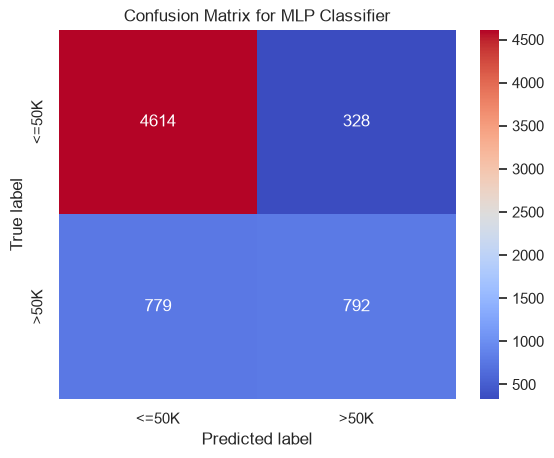

Accuracy: 0.8300322432058959
Precision: 0.7813481762072528
Recall: 0.7188838006553937
F-1-Score: 0.5886287625418061


In [20]:
# confusion matrix
class_labels = ["<=50K", ">50K"]
# Convert target labels to integer
y_test = y_test.astype(int)
y_pred = y_pred.astype(int)
cm = confusion_matrix(y_test, y_pred)
heatmap = sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm', annot_kws={"size": 12}, xticklabels=class_labels, yticklabels=class_labels)
heatmap.set_xlabel("Predicted label")
heatmap.set_ylabel("True label")
plt.title(f"Confusion Matrix for {model_name}")
plt.show()

# accuracy, precision, recall
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='macro'))
print("Recall:", recall_score(y_test, y_pred, average='macro')) 

# f-beta-score (a higher beta gives more weight to recall)
beta = 1
print(f"F-{beta}-Score:", fbeta_score(y_test, y_pred, beta=beta))

Notes:

* 

### Interpretability

**TASK 5: How do you evaluate your model's reasoning? Are there any improvements required?**

#### Feature Importance
Feature importance should always be interpreted with caution because it can be imprecise and does not tell us *how* the features are used. However, it can give us a broad indication of how the model comes to its conclusions.
* `Linear Regression`: Feature importance can be directly obtained from the **coefficients**. Remember that our feature encoding was 0 for white (vs. 1 for others) and 0 for women (vs. 1 for men)
* `Decision Tree` and `Random Forest`: Feature importance is measured by the amount of reduction in the Gini **impurity** (see decision tree above). However, this only includes absolute values and does not give an indication about the features "direction".
* `MLP Classifier`: due to the blackbox behavior of ANNs, we need to rely on **LIME** to provide local feature importance (of selected individuals). In this case, the feauture importance refers to a random instance. Feature and Value describe the individual's feature values. Prediction probabilities specify the classification certainty. The bar chart approximates each feature's contribution to the classification outcome. Run the method a few times to get an intuition for LIME explanations.

In [21]:
# feature importance
if selected_model == mlp:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        # instantiate LIME explainer
        explainer = lime_tabular.LimeTabularExplainer(
            training_data=np.array(X_train_df),
            feature_names=X_train_df.columns,
            class_names=y_train.unique().astype(str),
            mode='classification'
        )

        # explain a random instance
        exp = explainer.explain_instance(
            data_row=X_test_df.iloc[np.random.randint(0, len(X_test_df))].to_numpy(),
            predict_fn=selected_model.predict_proba
        )

        # Erzeuge das HTML-Dokument mit einem begrenzten weiß gefärbten Bereich
        html_str = exp.as_html()
        html_str = html_str.replace('<body>', '<body><style>.lime {background-color: white;padding:10px;margin-right:-20px}</style>')

        # Füge einen Titel hinzu
        title = '<h1>Feature Importance for MLPClassifier</h1>'
        html_str = html_str.replace('<body>', f'<body>{title}')

        # Zeige das HTML-Dokument im Notebook an
        display(HTML(html_str))

else:
    plt.figure(figsize=(12, 6))
    name = ""

    if selected_model == lr:
        name = "Linear Regression"
        feature_importance = lr.coef_

    elif selected_model == dt or selected_model == rf:
        feature_importance = selected_model.feature_importances_
        if selected_model == dt: 
            name = "Decision Tree"
        elif selected_model == rf: 
            name = "Random Forest"
            
    plt.bar(range(X_train_df.shape[1]), feature_importance)
    plt.xticks(range(X_train_df.shape[1]), X_train_df.columns, rotation=90)
    plt.xlabel('Feature')
    plt.ylabel('Feature Importance')
    plt.title(f"Feature Importance for {name}")
    plt.show()

#### Decision Tree
Decision trees can have meaningful decision rules that humans are able to interpret. However, it is not always too intuitive. Here are some explanations for the lines of each box:
* **First line**: decision rule with feature name and feature threshold
* **Second line**: Gini scores quantify the purity of a node, i.e., how dispersely the samples are distributed. The purer the node the darker the color.
* **Third line**: samples show the proportion of total samples handled in the current node
* **Fourth line**: distribution of how many samples fall into each class (left value refers to <=50K, the right value to >50K)
* **Fifth line**: majority class of the samples handled in the current node

In [22]:
# decision tree
if selected_model == dt:    
    fig = plt.figure(figsize=(16, 8))
    plot_tree(dt, feature_names = X_train_df.columns, class_names = class_labels, max_depth=3, fontsize=9, proportion=True, filled=True, rounded=True)

Notes:

* 

### Fairness
You learned that performance is not the only criterion to evaluate. For example, high accuracy can still introduce imbalanced effects for demographic groups. Below is a list of available group fairness metrics that you can select from:

- `accuracy` compares the model's accuracy between sensitive groups
- `selection_rate` compares the rate of positively classified samples (corresponds to **demographic parity**)
- `true positive rate`: difference between true positive rates (corresponds to **equality of opportunity**)
- `false positive rate`: difference between false positive rates (in combination with the true positive rate this corresponds to **equalized odds**)

**TASK 6: How do you evaluate your model's fairness? How does it compare to your colleagues' models? Are there any interventions required?**

In [23]:
# select the fairness metrics you want to evaluate
fairness_metrics = {
    "accuracy": accuracy_score,
    "selection_rate": flm.selection_rate,
    "false_positive_rate": flm.false_positive_rate,
    "false_negative_rate": flm.false_negative_rate
}

Differences for feature race:
 accuracy               0.067245
selection_rate         0.088590
false_positive_rate    0.041986
false_negative_rate    0.062251
dtype: float64


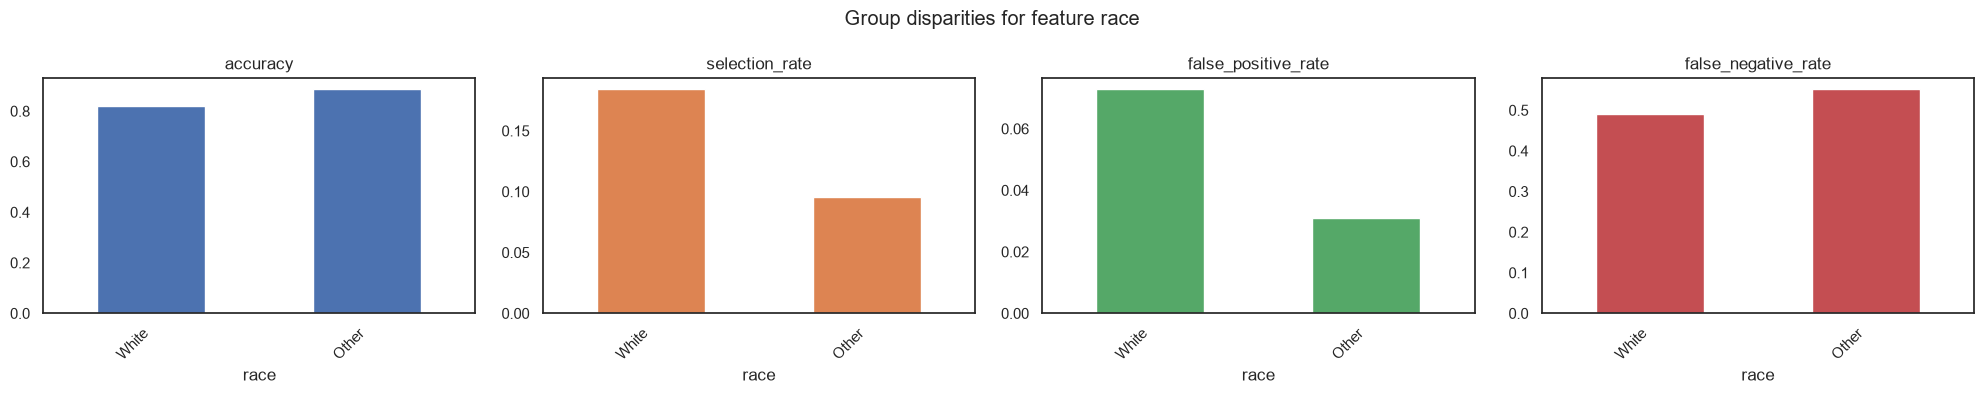

Differences for feature sex:
 accuracy               0.107087
selection_rate         0.212703
false_positive_rate    0.092164
false_negative_rate    0.375241
dtype: float64


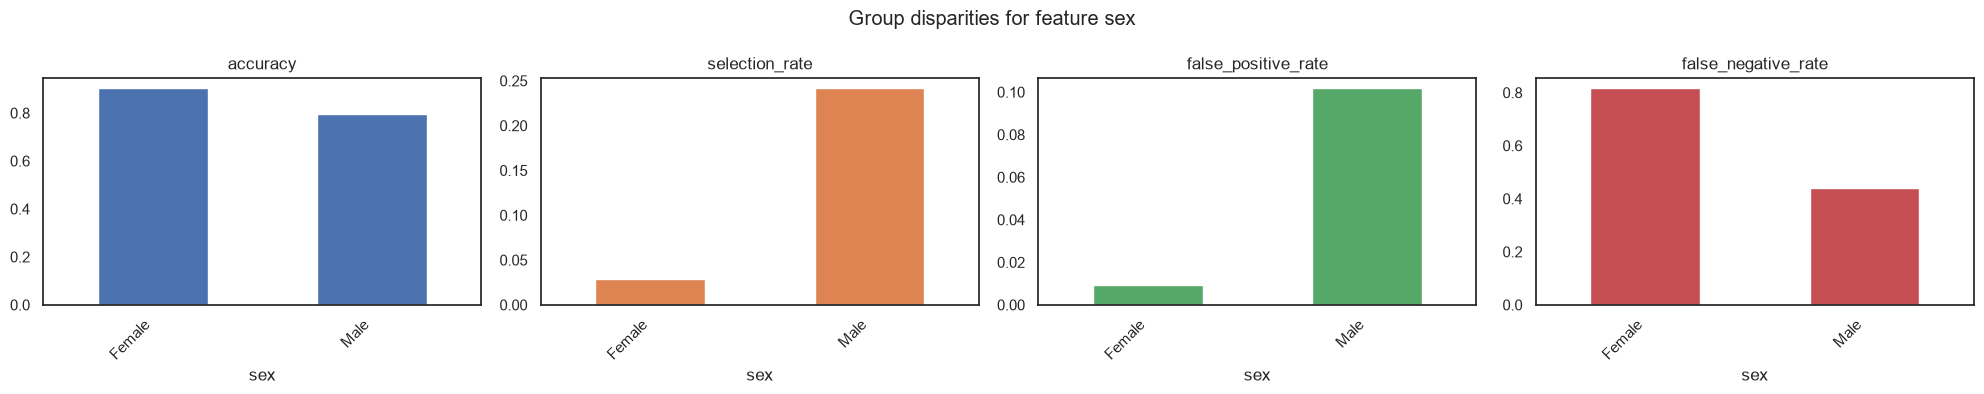

In [24]:
# separate selected sensitive features for targeted training
X_test_unsensitive = X_test_df[[col for col in X_train_df.columns if col not in selected_sensitive_features]]
X_test_sensitive = X_test_df[selected_sensitive_features]

# Create mappings for sensitive feature categories
inverse_sex_mapping = {v: k.strip() for k, v in sex_mapping.items()}
inverse_race_mapping = {v: k.strip() for k, v in race_mapping.items()}
inverse_age_mapping = {v: f"{10 + v*10}-{10 + (v+1)*10}" for v in range(8)}
# Create dictionary of all inverse mappings for easy access
feature_mappings = {
    'sex': inverse_sex_mapping,
    'race': inverse_race_mapping,
    'age': inverse_age_mapping
}

# plot fairness evaluation
for feature in selected_sensitive_features:
    
    metricframe_unmitigated = flm.MetricFrame(
        metrics=fairness_metrics,
        y_true=y_test,
        y_pred=y_pred,
        sensitive_features=X_test_sensitive[feature],
        )

    print(f"Differences for feature {feature}:\n {metricframe_unmitigated.difference()}")

    # Create the plot
    ax = metricframe_unmitigated.by_group.plot.bar(
        subplots=True,
        sharey=False,
        title=(f"Group disparities for feature {feature}"), 
        layout=[1, len(fairness_metrics)], 
        figsize=[20, 4], 
        legend=None
    )
    
# Apply inverse mappings to x-axis labels
    mapping = feature_mappings.get(feature, {})
    for subplot in ax.flatten():
        # Get the numeric group indices from the plot data
        current_labels = subplot.get_xticklabels()
        new_labels = []
        for tick in subplot.get_xticks():
            # Convert tick position to int, then map it
            idx = int(tick) if tick.is_integer() else int(round(tick))
            label = mapping.get(idx, str(idx))
            new_labels.append(label)
        subplot.set_xticklabels(new_labels, rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()

Notes:

* 

## Unfairness Mitigation

* **Balancing imbalanced data**: By oversampling underrepresented instances (e.g., black women), we can artificially increase the representation of underrepresented classes. Ideally, we should collect more data of underrepresented classes in order to improve performance for them.

* **Removing correlations with sensitive attributes**: If we want to nullify any influence of sensitive attributes, we should not only remove them from our data. Instead, we need to also account for correlations.

* **Penalty terms or regularization**: Introducing penalty terms or regularization for unwanted behavior (e.g, use of sensitive attributes) during the training process can guide models to pay particular attention to performance on the underrepresented class.

* **Optimizing for fairness metrics**: With the Fairlearn library we can optimize our classifiers to adhere to specified fairness metrics. However, due to the "impossibility of fairness" we need to make a judgement call about which metric to optimize.

* **Overruling decisions**: In human-AI hybrid settings, human experts can manually overrule a model's classification. They can account for contextual factors that are not captured in the data.

Since we cannot change the data and are restricted to this notebook, we will use the Fairlearn package to optimize a specified fairness metric.

**TASK 7: How do you want to improve fairness? Which fairness metric do you want to optimize? How do the classifications change?**

### Optimizing for Fairness Metrics
Due to technical constraints, only `Linear Regression`, `DecisionTree` and `RandomForest` models can be enhanced with Fairlearn mitigations. Of course, you can also argue that optimizing for accuracy is the way to go anayways, which makes this section obsolete.
- `accuracy_score`: regular accuracy score
- `balanced_accuracy_score`: equal accuracy for all sensitive groups
- `demographic_parity` equalizes the rate of positively classified samples
- `true_positive_rate_parity`: equalizes true positive rates (corresponds to **equality of opportunity**)
- `false_positive_rate_parity`: equalizes false positive rates (in combination with the true positive rate this corresponds to **equalized odds**)

In [25]:
# select the primary training objective ("accuracy_score", "balanced_accuracy_score", "selection_rate", "true_positive_rate", "true_negative_rate")
primary_objective = "accuracy_score"

# select the equality metric you want to use as a constraint ("demographic_parity", "true_positive_rate_parity", "false_negative_rate_parity")
fairness_metric = "demographic_parity"

In [26]:
# separate selected sensitive features for targeted training
X_train_unsensitive = X_train_df[[col for col in X_train_df.columns if col not in selected_sensitive_features]]
X_train_sensitive = X_train_df[selected_sensitive_features]

# train reconfigured model (only for lr, dt, and rf)
mitigated_model = ThresholdOptimizer(estimator=selected_model, constraints=fairness_metric, objective=primary_objective)
mitigated_model.fit(X_train_unsensitive, y_train, sensitive_features=X_train_sensitive)
y_pred_mitigated = mitigated_model.predict(X_test_df[X_train_unsensitive.columns], sensitive_features=X_test_df[selected_sensitive_features])

### Fairness Evaluation

Differences for feature race:
 accuracy               0.059622
selection_rate         0.008109
false_positive_rate    0.022881
false_negative_rate    0.117701
dtype: float64


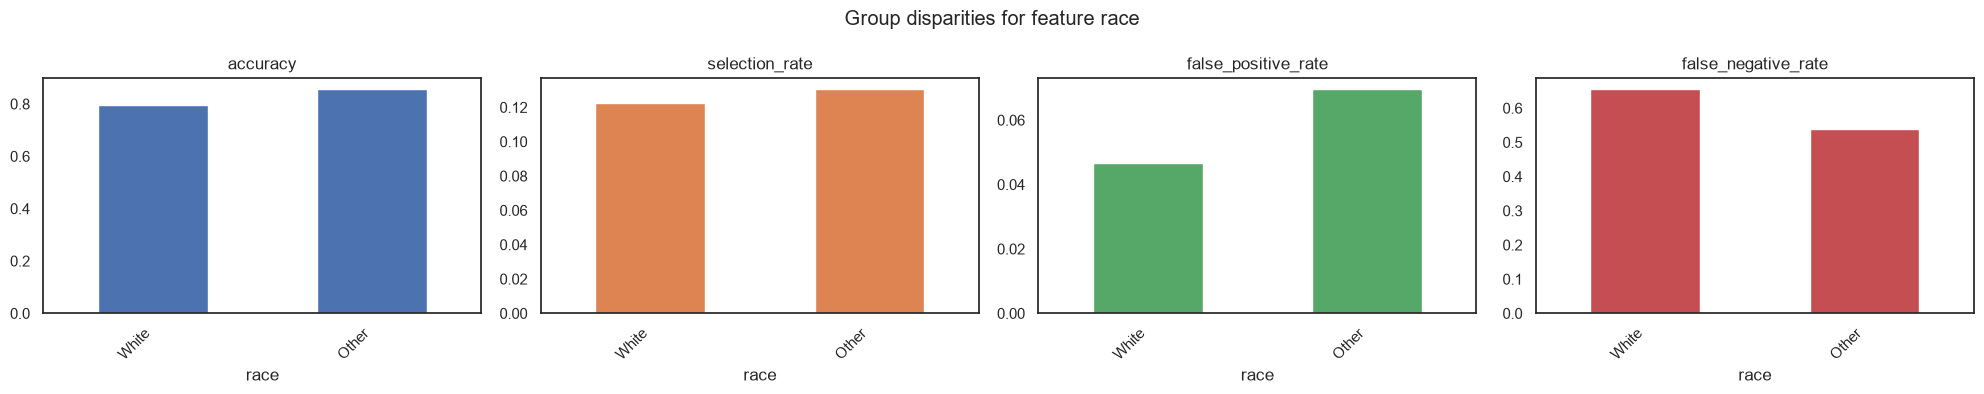

Differences for feature sex:
 accuracy               0.094463
selection_rate         0.006353
false_positive_rate    0.045913
false_negative_rate    0.112826
dtype: float64


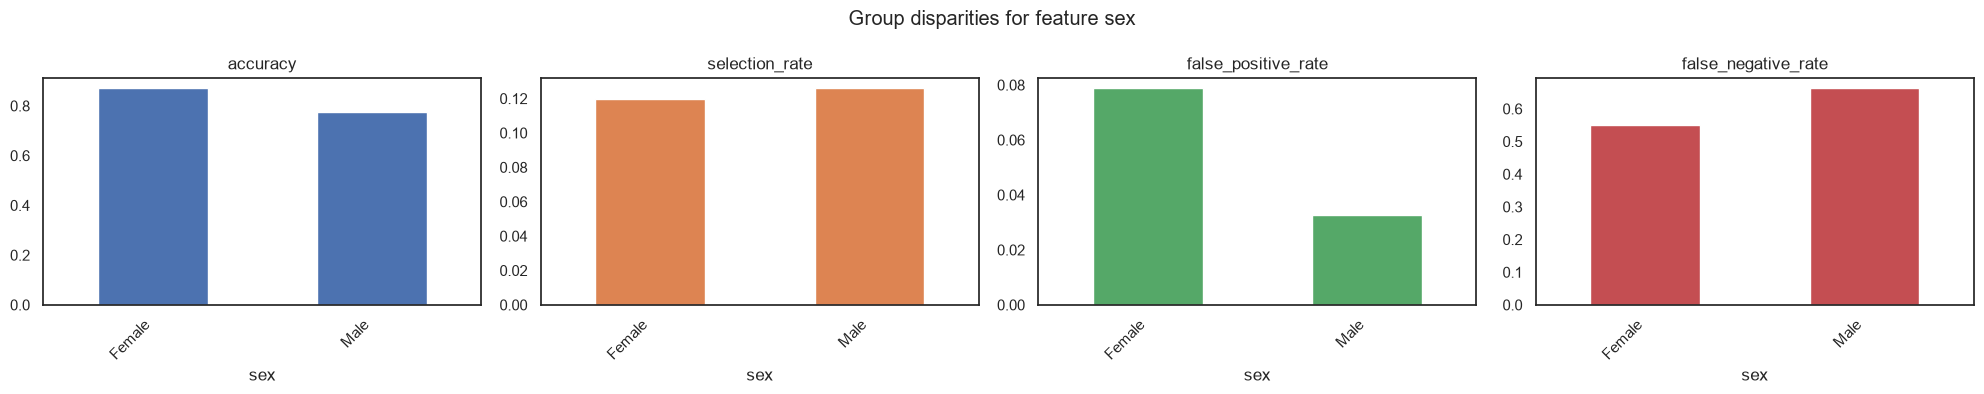

In [27]:
# plot fairness evaluation for reconfigured model (only for lr, dt, and rf)

for feature in selected_sensitive_features:
    
    metricframe_mitigated = flm.MetricFrame(
        metrics=fairness_metrics,
        y_true=y_test,
        y_pred=y_pred_mitigated,
        sensitive_features=X_test_sensitive[feature],
        )

    print(f"Differences for feature {feature}:\n {metricframe_mitigated.difference()}")

    # Create the plot
    ax = metricframe_mitigated.by_group.plot.bar(
        subplots=True,
        sharey=False,
        title=(f"Group disparities for feature {feature}"), 
        layout=[1, len(fairness_metrics)], 
        figsize=[20, 4], 
        legend=None
    )
    
# Apply inverse mappings to x-axis labels
    mapping = feature_mappings.get(feature, {})
    for subplot in ax.flatten():
        # Get the numeric group indices from the plot data
        current_labels = subplot.get_xticklabels()
        new_labels = []
        for tick in subplot.get_xticks():
            # Convert tick position to int, then map it
            idx = int(tick) if tick.is_integer() else int(round(tick))
            label = mapping.get(idx, str(idx))
            new_labels.append(label)
        subplot.set_xticklabels(new_labels, rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()

Notes:

* 

## Deployment

Finally, it is time to put your model into practice. Or is it?

**TASK 8: Would you deploy your model in practice? If not, what would be required to do so? Would you maybe choose an entirely different approach to solve the use case?**

Notes:

* 